In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importation de la bibliothèque pour connecter Google Drive à Colab
from google.colab import drive
# Appliquation du style propre aux graphiques
sns.set_theme(style="whitegrid")

In [3]:

# Étape 1 : Connexion (montage) de votre Google Drive sur l'environnement Colab
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Étape 2 : Chargement du fichier CSV depuis votre Drive dans une variable 'df'
df = pd.read_csv("/content/drive/MyDrive/HRDataset_v14.csv")

In [5]:
# Étape 3 : Affichage des 5 premières lignes du jeu de données pour vérifier l'importation
df.head()

,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,...,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,...,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,...,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,...,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,...,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [6]:
#  Étape 4 : Vérification du nombre de lignes doublons
nb_doublons = df.duplicated().sum()
print(f"Nombre de lignes exactement doublonnées : {nb_doublons}")

Nombre de lignes exactement doublonnées : 0


In [7]:
# Étape 5 : Vérification des doublons sur l'identifiant unique de l'employé (EmpID)
doublons_id = df.duplicated(subset=['EmpID']).sum()
print(f"Nombre d'employés avec un EmpID en doublon : {doublons_id}")

Nombre d'employés avec un EmpID en doublon : 0


In [8]:
#Étape 6 : Nettoyage des doublons (priorité à la clé primaire si présente)
if doublons_id > 0:
    df = df.drop_duplicates(subset=['EmpID'], keep='first')
else:
    df = df.drop_duplicates()

In [9]:
# Étape 7 : Traitement des valeurs manquantes (Imputation) ---
# Imputation textuelle pour la date de fin de contrat
df['DateofTermination'] = df['DateofTermination'].fillna("Actif")

# Imputation numérique pour l'identifiant du Manager
df['ManagerID'] = df['ManagerID'].fillna(-1)

In [10]:
# Étape 8 : Normalisation du texte ---
# Suppression des espaces superflus (Leading/Trailing whitespaces)
df['PerformanceScore'] = df['PerformanceScore'].astype(str).str.strip()

In [11]:
# Étape 9 : Afficher un résumé technique du jeu de données :
# - Nombre total de lignes et de colonnes
# - Noms des colonnes
# - Nombre de valeurs non nulles (pour repérer s'il manque des données)
# - Type de chaque colonne (nombre entier int64, nombre décimal float64, texte object)
print("--- INFORMATIONS GÉNÉRALES ---")
df.info()



--- INFORMATIONS GÉNÉRALES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    object 
 1   EmpID                       311 non-null    int64  
 2   MarriedID                   311 non-null    int64  
 3   MaritalStatusID             311 non-null    int64  
 4   GenderID                    311 non-null    int64  
 5   EmpStatusID                 311 non-null    int64  
 6   DeptID                      311 non-null    int64  
 7   PerfScoreID                 311 non-null    int64  
 8   FromDiversityJobFairID      311 non-null    int64  
 9   Salary                      311 non-null    int64  
 10  Termd                       311 non-null    int64  
 11  PositionID                  311 non-null    int64  
 12  Position                    311 non-null    object 
 13  Stat

In [12]:
print("\n--- DIMENSIONS DU TABLEAU ---")
# df.shape renvoie un tuple : (nombre_de_lignes, nombre_de_colonnes)
print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")


--- DIMENSIONS DU TABLEAU ---
Nombre de lignes : 311
Nombre de colonnes : 36


In [13]:
# Étape 10 : Pour les employés toujours en poste, nous remplaçons la date de départ manquante par "Actif"
df['DateofTermination'] = df['DateofTermination'].fillna("Actif")

In [14]:
# Étape 11 : Pour les 8 managers manquants, nous remplaçons par une valeur neutre (-1) pour éviter les erreurs de calcul
df['ManagerID'] = df['ManagerID'].fillna(-1)

In [15]:
# Étape 12 : Vérification : s'assurer qu'il n'y a plus de valeurs manquantes imprévues
print("\nNombre de valeurs manquantes restantes par colonne :")
print(df[['DateofTermination', 'ManagerID', 'PerformanceScore']].isnull().sum())


Nombre de valeurs manquantes restantes par colonne :
DateofTermination    0
ManagerID            0
PerformanceScore     0
dtype: int64


In [16]:
# Étape 13 : Nettoyage des espaces superflus dans la colonne PerformanceScore
df['PerformanceScore'] = df['PerformanceScore'].astype(str).str.strip()

In [17]:
# Étape 14 : Affichage des catégories uniques de performance pour vérifier la cohérence
print("\nCatégories uniques de performance après nettoyage :")
print(df['PerformanceScore'].value_counts())


Catégories uniques de performance après nettoyage :
PerformanceScore
Fully Meets          243
Exceeds               37
Needs Improvement     18
PIP                   13
Name: count, dtype: int64


In [18]:
# Étape 15 : Sélection des colonnes numériques pertinentes pour l'analyse RH
cols_analyse = ['Salary', 'PerfScoreID', 'EngagementSurvey', 'EmpSatisfaction', 'SpecialProjectsCount', 'Absences']



In [19]:
# Étape 16 : Affichage des statistiques descriptives (arrondies à 2 décimales pour la lisibilité)
# - count : nombre d'employés
# - mean : moyenne
# - std : écart-type (dispersion)
# - min / max : valeurs extrêmes
# - 50% : médiane
df[cols_analyse].describe().round(2)

,Salary,PerfScoreID,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,Absences
count,311.00,311.00,311.00,311.00,311.00,311.00
mean,69020.68,2.98,4.11,3.89,1.22,10.24
std,25156.64,0.59,0.79,0.91,2.35,5.85
min,45046.00,1.00,1.12,1.00,0.00,1.00
25%,55501.50,3.00,3.69,3.00,0.00,5.00
50%,62810.00,3.00,4.28,4.00,0.00,10.00
75%,72036.00,3.00,4.70,5.00,0.00,15.00
max,250000.00,4.00,5.00,5.00,8.00,20.00


In [1]:
# Étape 16 :
# 1. Déclaration de la figure et de l'axe
fig, ax = plt.subplots(figsize=(8, 5))

# 2. Construction du graphique en barres
sns.countplot(
    data=df,
    x='PerformanceScore',
    order=['Exceeds', 'Fully Meets', 'Needs Improvement', 'PIP'],
    palette="Blues_r",
    ax=ax
)

# 3. Ajout du Titre et des axes sur l'objet 'ax'
ax.set_title("Répartition des Employés par Niveau de Performance", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Niveau de Performance", fontsize=11, fontweight='bold')
ax.set_ylabel("Nombre d'Employés", fontsize=11, fontweight='bold')

# 4. Ajustement et Affichage du graphique
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [21]:
#Étape 17 :
# 4. Ajout des étiquettes de valeurs au-dessus de chaque barre
for p in ax.patches:
    height = p.get_height()
    # On vérifie que la hauteur existe et est supérieure à 0
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

In [22]:
# 5. Affichage propre du graphique
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

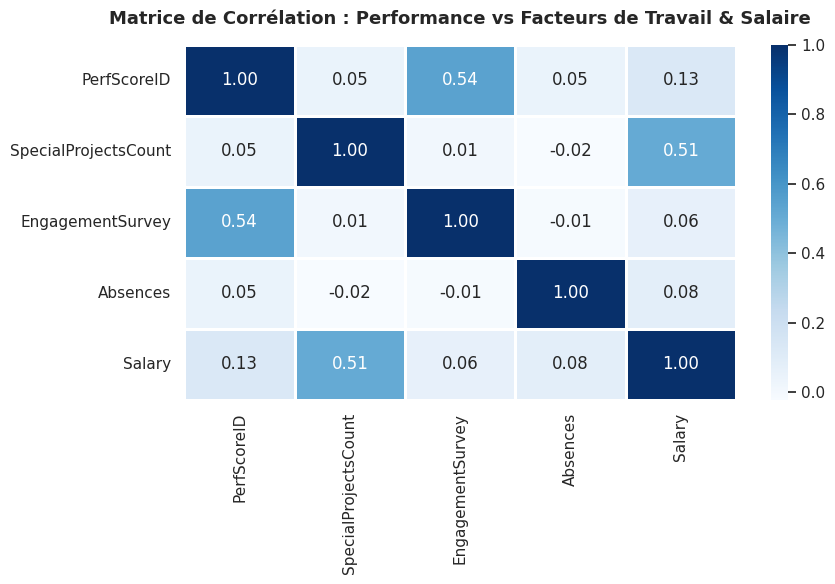

In [27]:


# 1. Sélection des variables quantitatives
variables_cles = ['PerfScoreID', 'SpecialProjectsCount', 'EngagementSurvey', 'Absences', 'Salary']

# 2. Calcul de la matrice de corrélation
matrice_corr = df[variables_cles].corr()

# 3. Définition de la figure et de l'axe
fig, ax = plt.subplots(figsize=(9, 6))

# 4. Génération de la Heatmap
sns.heatmap(
    matrice_corr,
    annot=True,
    cmap='Blues',
    fmt=".2f",
    linewidths=0.8,
    cbar=True,
    ax=ax
)

# 5. Titre via l'objet ax
ax.set_title("Matrice de Corrélation : Performance vs Facteurs de Travail & Salaire", fontsize=13, fontweight='bold', pad=15)

# Ajustement et Affichage
plt.tight_layout()
plt.show()

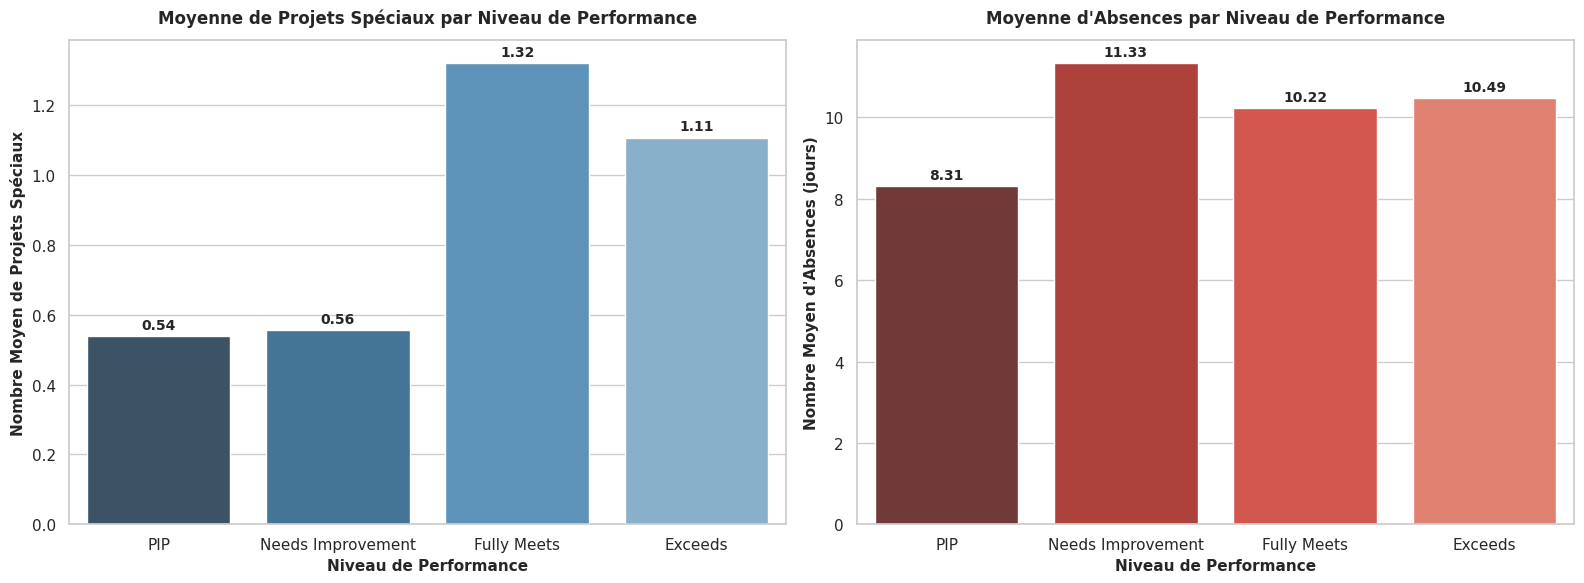

In [28]:

# 1. Création d'une figure contenant 2 sous-graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ordre d'affichage des catégories de performance sur l'axe x
ordre_perf = ['PIP', 'Needs Improvement', 'Fully Meets', 'Exceeds']

# --- Graphique 1 : Nombre moyen de Projets Spéciaux par Niveau de Performance ---
sns.barplot(
    data=df,
    x='PerformanceScore',
    y='SpecialProjectsCount',
    order=ordre_perf,
    hue='PerformanceScore',
    palette='Blues_d',
    legend=False,
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Moyenne de Projets Spéciaux par Niveau de Performance", fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel("Niveau de Performance", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Nombre Moyen de Projets Spéciaux", fontsize=11, fontweight='bold')

# Ajout des étiquettes de valeur sur le 1er graphique
for p in axes[0].patches:
    valeur = p.get_height()
    if valeur > 0:
        axes[0].annotate(
            f'{valeur:.2f}',
            (p.get_x() + p.get_width() / 2., valeur),
            ha='center', va='bottom', fontsize=10, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

# --- Graphique 2 : Nombre moyen d'Absences par Niveau de Performance ---
sns.barplot(
    data=df,
    x='PerformanceScore',
    y='Absences',
    order=ordre_perf,
    hue='PerformanceScore',
    palette='Reds_d',
    legend=False,
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Moyenne d'Absences par Niveau de Performance", fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel("Niveau de Performance", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Nombre Moyen d'Absences (jours)", fontsize=11, fontweight='bold')

# Ajout des étiquettes de valeur sur le 2ème graphique
for p in axes[1].patches:
    valeur = p.get_height()
    if valeur > 0:
        axes[1].annotate(
            f'{valeur:.2f}',
            (p.get_x() + p.get_width() / 2., valeur),
            ha='center', va='bottom', fontsize=10, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

# Ajustement automatique de la disposition
plt.tight_layout()
plt.show()

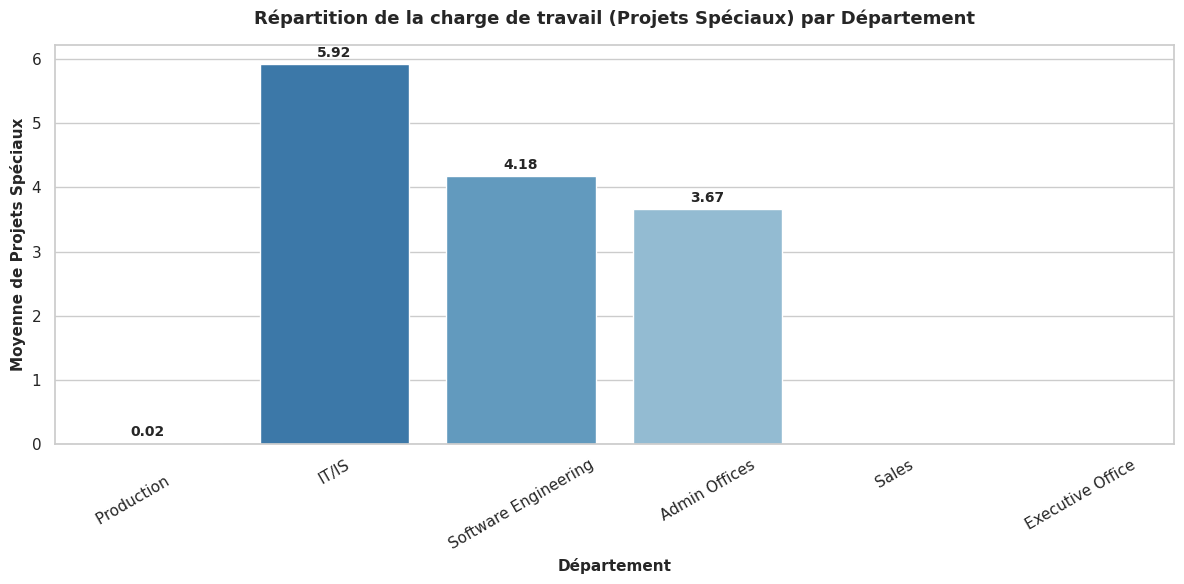

In [25]:
# 1. Configuration de la figure et des axes (Approche Orientée Objet)
fig, ax = plt.subplots(figsize=(12, 6))

# 2. Graphique en barres
sns.barplot(
    data=df,
    x='Department',
    y='SpecialProjectsCount',
    hue='Department',
    palette='Blues_r',
    legend=False,
    errorbar=None,
    ax=ax
)

# 3. Personnalisation des titres et axes
ax.set_title("Répartition de la charge de travail (Projets Spéciaux) par Département", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Département", fontsize=11, fontweight='bold')
ax.set_ylabel("Moyenne de Projets Spéciaux", fontsize=11, fontweight='bold')
ax.tick_params(axis='x', rotation=30)

# 4. Ajout des valeurs au-dessus des barres
for p in ax.patches:
    valeur = p.get_height()
    if valeur > 0:
        ax.annotate(
            f'{valeur:.2f}',
            (p.get_x() + p.get_width() / 2., valeur),
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

# Affichage propre
plt.tight_layout()
plt.show()

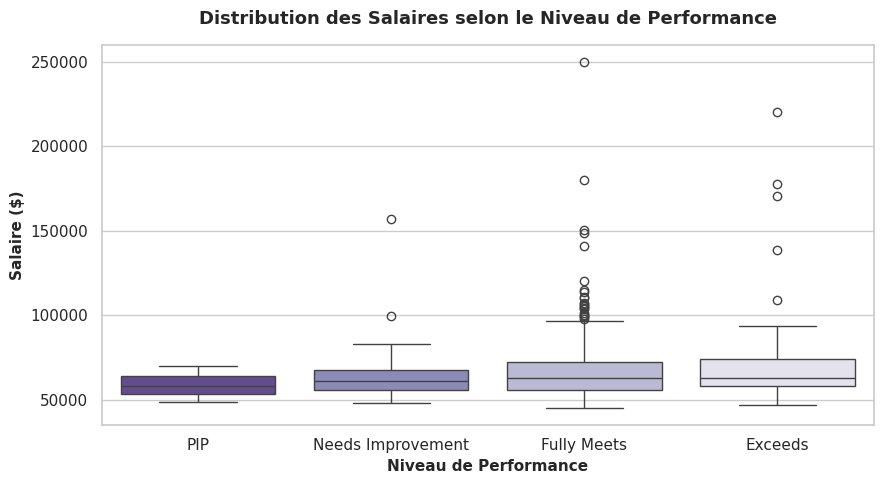

In [26]:
# 1. Configuration de la figure et de l'axe
fig, ax = plt.subplots(figsize=(9, 5))

# Ordre d'affichage logique des niveaux de performance
ordre_perf = ['PIP', 'Needs Improvement', 'Fully Meets', 'Exceeds']

# 2. Boxplot : Distribution des salaires par performance
sns.boxplot(
    data=df,
    x='PerformanceScore',
    y='Salary',
    order=ordre_perf,
    hue='PerformanceScore',
    palette='Purples',
    legend=False,
    ax=ax
)

# 3. Personnalisation des titres et axes
ax.set_title("Distribution des Salaires selon le Niveau de Performance", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Niveau de Performance", fontsize=11, fontweight='bold')
ax.set_ylabel("Salaire ($)", fontsize=11, fontweight='bold')

# Affichage propre
plt.tight_layout()
plt.show()